In [3]:
%load_ext autoreload
%autoreload 2
import numpy as np
import emcee
import corner
from matplotlib import pyplot as plt
from astropy import units as u
from astropy import constants as const
import time
from multiprocessing import Pool
import pickle
import scipy
from matplotlib.lines import Line2D

from nfw_profile_heating import NFWProfile
from cluster_error_prop import Cluster_werr
from statistics_functions import log_lik
from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr
from plotting import savefig, paper_plot

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [4]:
with open('pickled/mcmc_001_16_20000_06-08-2024.pkl', 'rb') as h:
    mcmc_output = pickle.load(h)

(21328, 2)


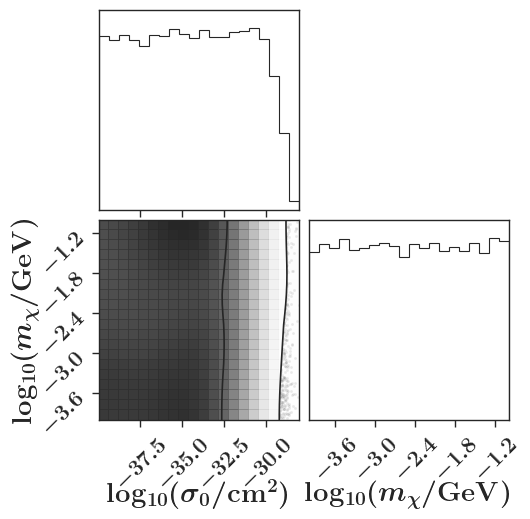

In [5]:
# create corner plot of results
paper_plot()

print(mcmc_output.shape)

labels = [r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$", r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$"]
fig = corner.corner(
    mcmc_output, labels=labels, dpi=450, smooth=3.5, levels=[0.68, 0.95]
);

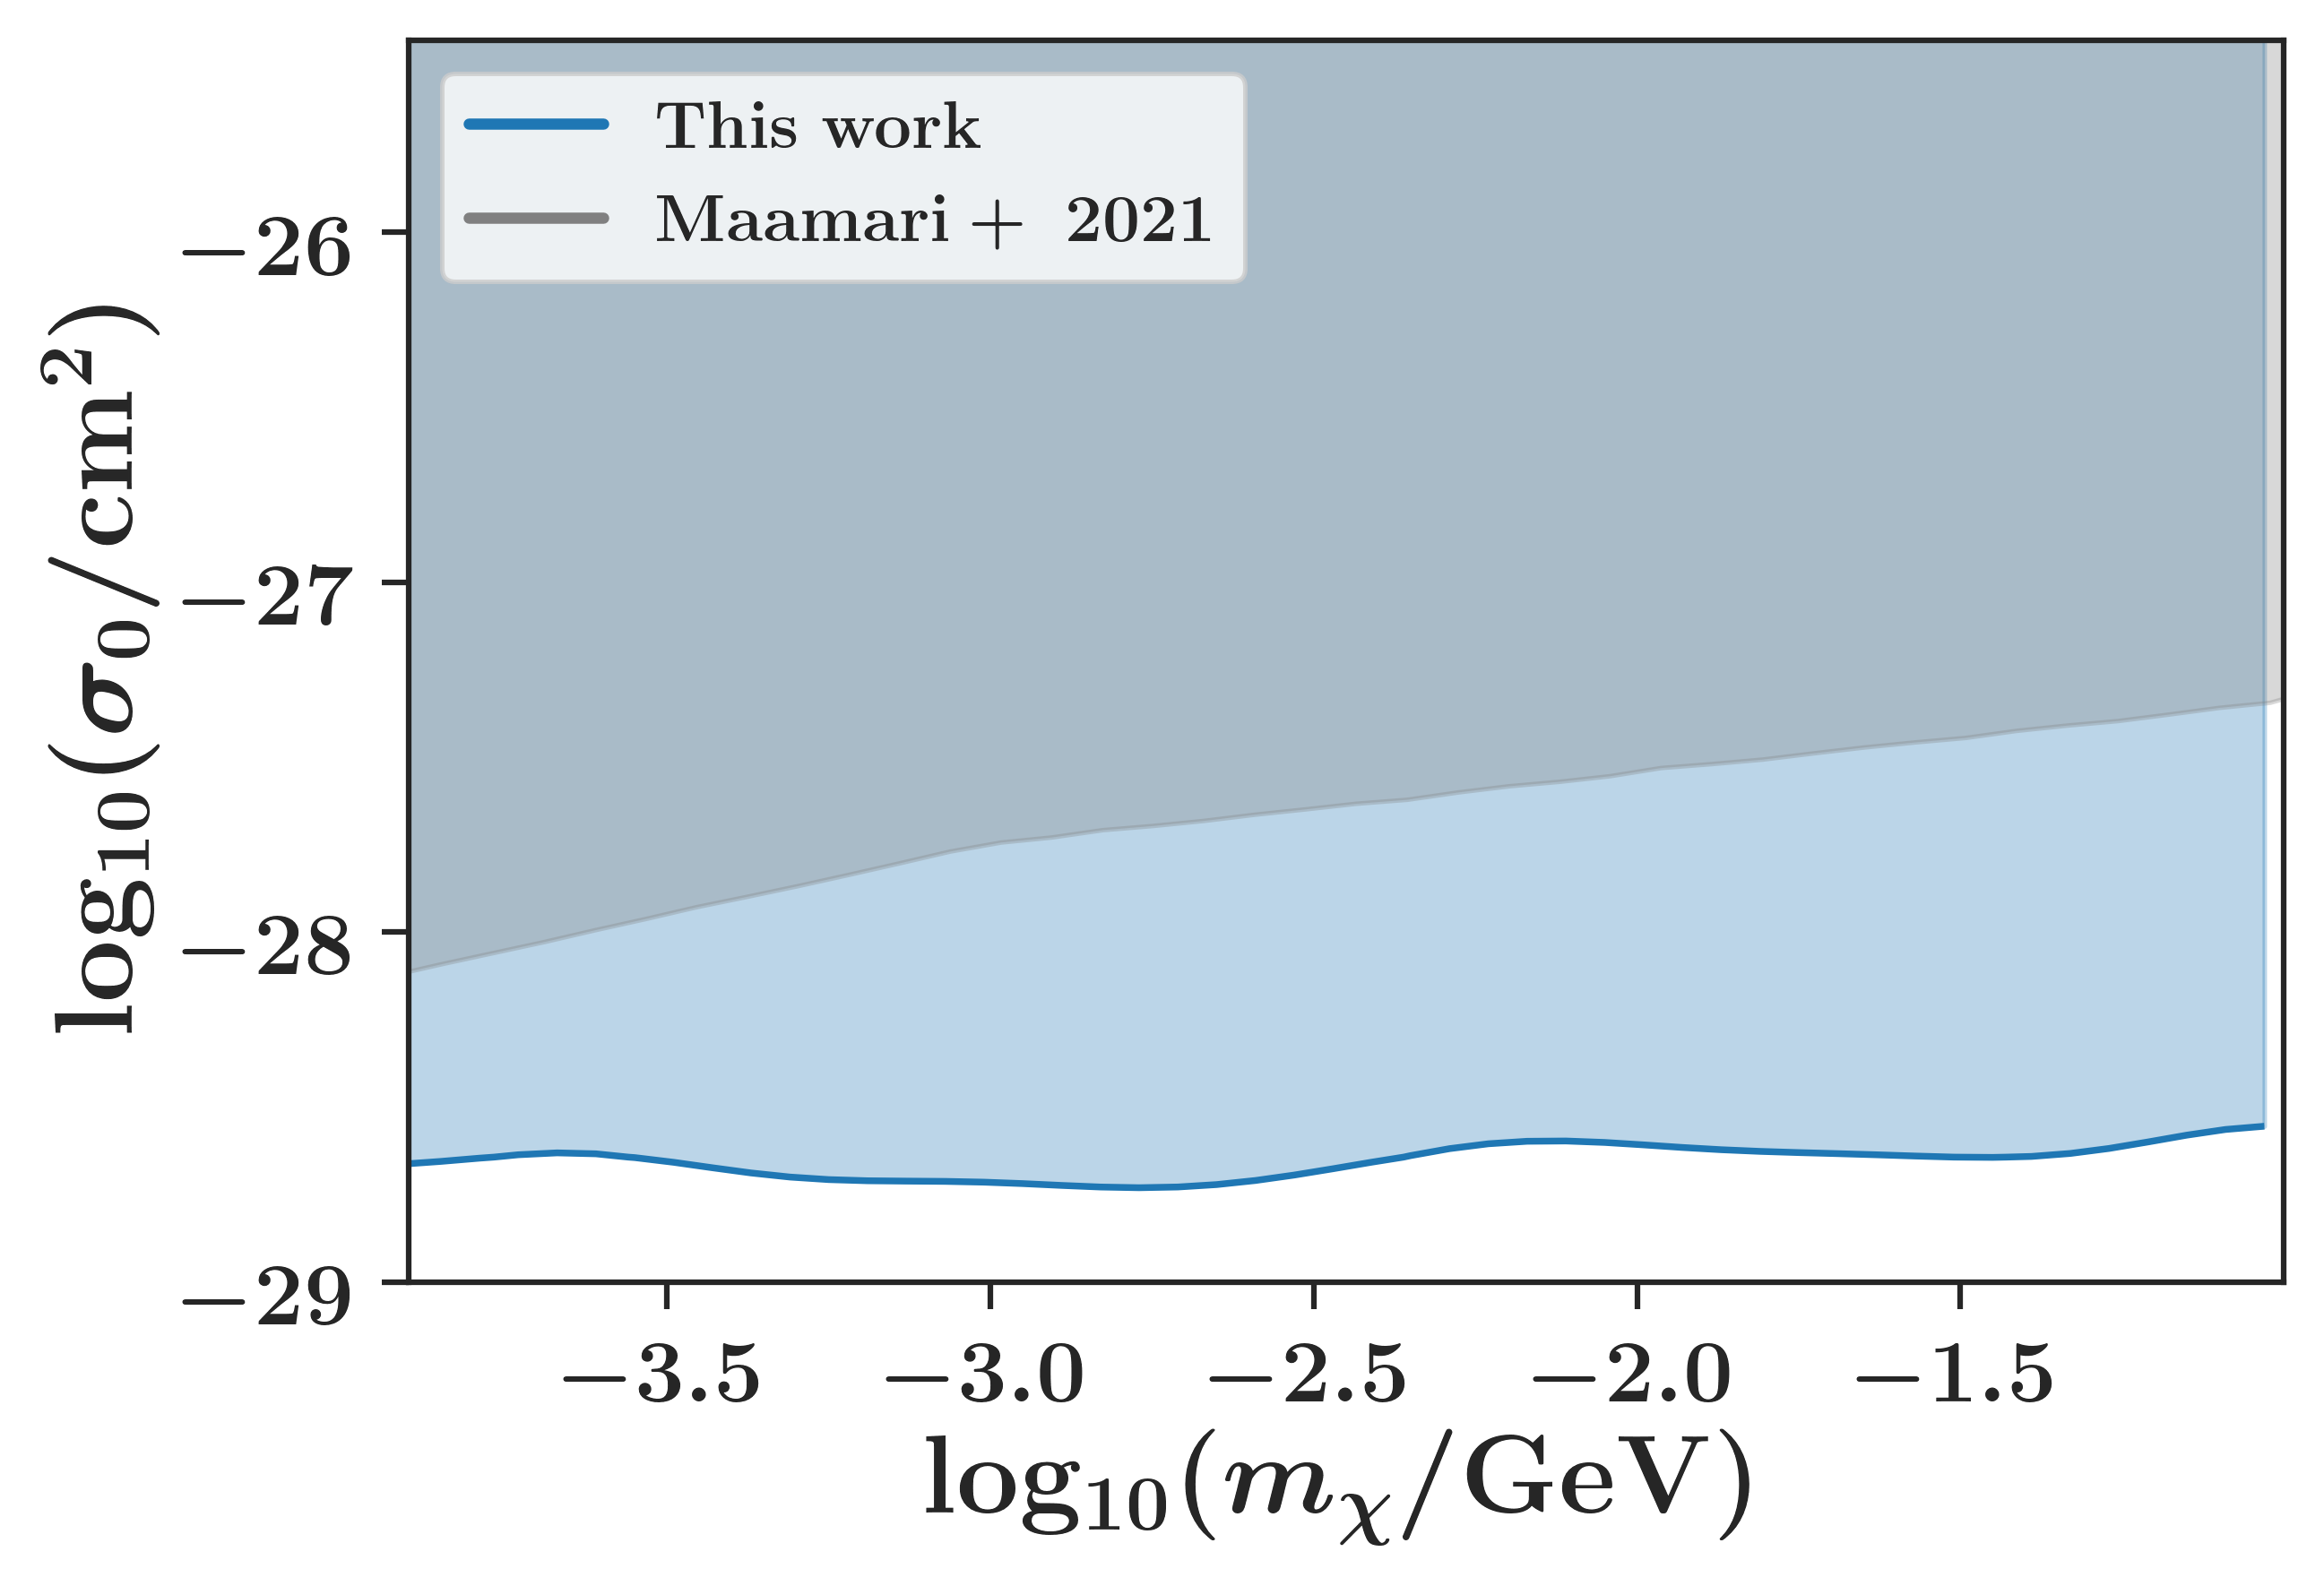

In [14]:
samples_coords = np.array([[x, y] for y, x in mcmc_output])

# Reshape to get a 2D array of samples
x_samples = samples_coords[:,0]
y_samples = samples_coords[:,1]

# Create a 2D histogram
nbins = 50
H, xedges, yedges = np.histogram2d(x_samples, y_samples, bins=nbins, density=True)

# Apply Gaussian smoothing
sigma = 3.5
H_smooth = scipy.ndimage.gaussian_filter(H, sigma=sigma)

# Compute the bin centers
xcenters = (xedges[:-1] + xedges[1:]) / 2
ycenters = (yedges[:-1] + yedges[1:]) / 2

# Create a meshgrid for the centers
X, Y = np.meshgrid(xcenters, ycenters)

# Flatten the smoothed histogram and sort the values
H_smooth_flat = H_smooth.flatten()
H_smooth_sorted = np.sort(H_smooth_flat)

# Calculate the cumulative distribution function (CDF)
cdf = np.cumsum(H_smooth_sorted)
cdf /= cdf[-1]  # Normalize

# Define the percentiles for contour levels
#percentiles = [50, 75, 90, 95]
#levels = np.percentile(H_smooth_sorted, percentiles)

# Find the 95th percentile value
percentile_value = np.percentile(H_smooth, 5)

# Generate the contour plot
plt.figure(dpi=450)#(figsize=(8, 6))
contour = plt.contour(X, Y, H_smooth.T, levels=[percentile_value],colors='#1f77b4')
#plt.colorbar(contour, label='Density')
#plt.contourf(X, Y, H_smooth.T, levels=[0,percentile_value], alpha=0.5,colors='#1f77b4')


path = contour.collections[0].get_paths()[0]
v = path.vertices
x = v[:,0]
y = v[:,1]

y2=-25
plt.fill_between(x, y, y2, where=(y2 >= y), interpolate=True, color='#1f77b4', alpha=0.3)



#plt.clabel(contour)
handles=[Line2D([0], [0], color='#1f77b4', lw=2, label=f'$\mathrm{{This~work}}$'),
        Line2D([0], [0], color='gray', lw=2, label=f"$\mathrm{{Maamari+~2021}}$")]

#plt.xlim(-4, -1)
#plt.ylim(-30, -25.5)


import pandas as pd
maamari = pd.read_csv('data/maamari_2021_constraint.csv', header=None)
plt.plot(maamari[0], maamari[1], label=f"$\mathrm{{Maamari+ 2021}}$", color='gray')

plt.legend(handles=handles, loc='upper left')
#plt.xlabel(r"$m_{\chi} \mathrm{(GeV)}$")
#plt.ylabel(r"$\sigma_0 (\mathrm{cm}^2)$")
plt.xlabel("DM particle mass (GeV)")
plt.ylabel(r"Interaction cross section (cm$^2$)")



plt.fill_between(
                    np.log10(maamari[0]), np.log10(maamari[1]),
                    y2=1e-26,
                    alpha=0.3, color='gray'
                )

# Customize the plot
#plt.title('95th Percentile Contour Plot')
plt.xlabel(r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$")
plt.ylabel(r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$")

# Show the plot

plt.xlim(-3.9, x_samples.max())
plt.ylim(-29, -25.45)
plt.show()


[]

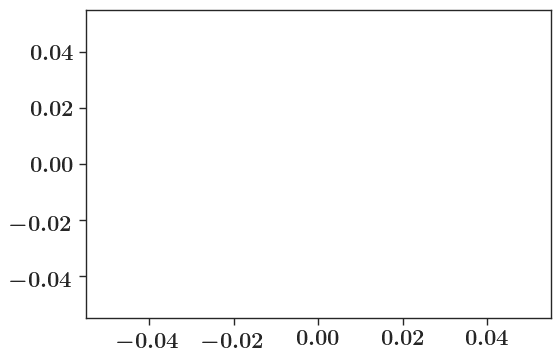

In [7]:
plt.plot()

In [8]:
Y.max()

-28.16539869349512

In [9]:
Line2D([0], [0], color='#1f77b4', lw=2, label=f'$\mathrm{{This~work}}$')

In [10]:
path = contour.collections[0].get_paths()[0]
v = path.vertices
x = v[:,0]
y = v[:,1]


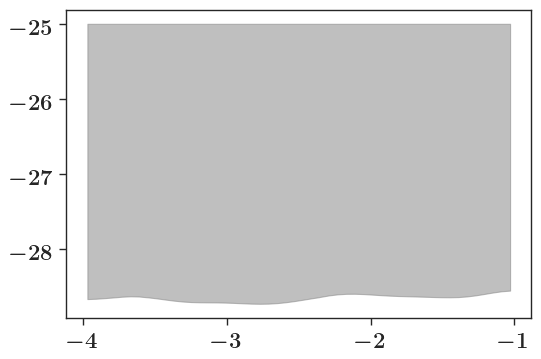

In [11]:
y2=-25
plt.fill_between(x, y, y2, where=(y2 >= y), interpolate=True, color='gray', alpha=0.5)

plt.show()